# BÁO CÁO THỰC HÀNH: DỰ ĐOÁN GIÁ NHÀ (HOUSE PRICE PREDICTION)
### Môn học: Machine Learning — Bài toán Hồi quy (Regression)
### Thuật toán: **Linear Regression** vs **Random Forest Regression**

Dataset: `House Price Prediction Dataset.csv` (nguồn Kaggle: https://www.kaggle.com/datasets/zafarali27/house-price-prediction-dataset)



## MỤC LỤC
1. Import thư viện & đọc dữ liệu
2. Input và Tiền xử lý dữ liệu
3. Triển khai và huấn luyện mô hình
4. So sánh hiệu năng & Lựa chọn mô hình


## 1. Import thư viện và đọc dữ liệu

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)

df = pd.read_csv("House Price Prediction Dataset.csv")
print("Kích thước dữ liệu:", df.shape)
df.head()
df.info()


Kích thước dữ liệu: (2000, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Id         2000 non-null   int64 
 1   Area       2000 non-null   int64 
 2   Bedrooms   2000 non-null   int64 
 3   Bathrooms  2000 non-null   int64 
 4   Floors     2000 non-null   int64 
 5   YearBuilt  2000 non-null   int64 
 6   Location   2000 non-null   object
 7   Condition  2000 non-null   object
 8   Garage     2000 non-null   object
 9   Price      2000 non-null   int64 
dtypes: int64(7), object(3)
memory usage: 156.4+ KB


In [2]:
#Thống kê mô tả dữ liệu 
df.describe()


,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Price
count,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000
mean,1000.500000,2786.209500,3.003500,2.55250,1.993500,1961.446000,537676.855000
std,577.494589,1295.146799,1.424606,1.10899,0.809188,35.926695,276428.845719
min,1.000000,501.000000,1.000000,1.00000,1.000000,1900.000000,50005.000000
25%,500.750000,1653.000000,2.000000,2.00000,1.000000,1930.000000,300098.000000
50%,1000.500000,2833.000000,3.000000,3.00000,2.000000,1961.000000,539254.000000
75%,1500.250000,3887.500000,4.000000,4.00000,3.000000,1993.000000,780086.000000
max,2000.000000,4999.000000,5.000000,4.00000,3.000000,2023.000000,999656.000000


**Nhận xét:** Bộ dữ liệu bao gồm 2000 dòng, 10 cột (bao gồm `Id`) với đầy đủ giá trị ở tất cả các biến. Các biến định lượng có phạm vi giá trị phù hợp với bài toán dự đoán giá nhà: diện tích từ 501–4.999 ft², số phòng ngủ từ 1–5, số phòng tắm từ 1–4, số tầng từ 1–3, năm xây dựng từ 1900–2023 và giá nhà từ 50.005–999.656 USD. Giá trị trung bình và trung vị của các biến tương đối gần nhau, đồng thời độ lệch chuẩn phản ánh dữ liệu có mức độ phân tán hợp lý, tạo điều kiện thuận lợi cho việc xây dựng và đánh giá các mô hình dự đoán giá nhà.

## 2. Input và Tiền xử lý dữ liệu

**Ý nghĩa bài toán:** Định giá bất động sản tự động là một bài toán quan trọng trong thực tế, hỗ trợ người mua, người bán,
nhà đầu tư và ngân hàng ước lượng giá trị hợp lý của một căn nhà dựa trên các đặc trưng vật lý và vị trí, hạn chế tình
trạng định giá cảm tính, thiếu nhất quán.

**Biến Input (X) — 8 biến (5 biến số và 3 biến phân loại):**
| STT | Biến | Kiểu dữ liệu | Ý nghĩa |
|---|---|---|---|
| 1 | Area | Số nguyên (int64) | Diện tích căn nhà (sqft) |
| 2 | Bedrooms | Số nguyên (int64) | Số phòng ngủ |
| 3 | Bathrooms | Số nguyên (int64) | Số phòng tắm |
| 4 | Floors | Số nguyên (int64) | Số tầng |
| 5 | YearBuilt | Số nguyên (int64) | Năm xây dựng |
| 6 | Location | 	Chuỗi ký tự / văn bản (object) | Downtown / Suburban / Urban / Rural |
| 7 | Condition | 	Chuỗi ký tự / văn bản (object) | Excellent / Good / Fair / Poor |
| 8 | Garage | 	Chuỗi ký tự / văn bản (object) | Yes / No |

**Biến Output (Y):** `Price` — giá bán căn nhà (USD), biến số thực liên tục → xác định đây là bài toán **Hồi quy (Regression)**
thuộc nhóm Học có giám sát (Supervised Learning).


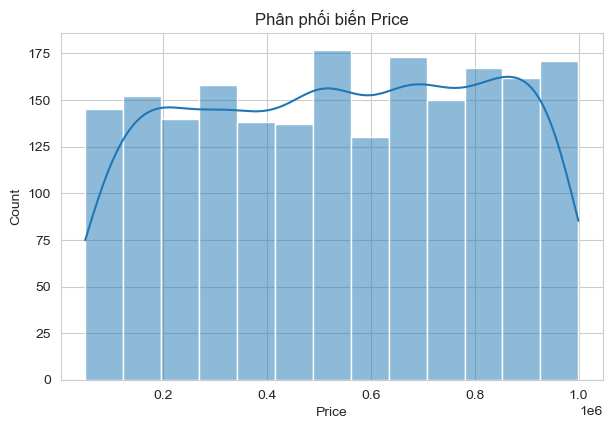

In [3]:
fig, ax = plt.subplots(figsize=(7,4.5))
sns.histplot(df["Price"], kde=True, ax=ax)
ax.set_title("Phân phối biến Price")
plt.show()


### Làm sạch dữ liệu:


In [4]:
# Kiểm tra giá trị thiếu (Missing values)
print("Số giá trị thiếu theo từng cột:")
print(df.isnull().sum())

Số giá trị thiếu theo từng cột:
Id           0
Area         0
Bedrooms     0
Bathrooms    0
Floors       0
YearBuilt    0
Location     0
Condition    0
Garage       0
Price        0
dtype: int64


In [5]:
# Kiểm định Outlier bằng phương pháp IQR (Interquartile Range)
def iqr_outlier_count(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((series < lower) | (series > upper)).sum()

numeric_cols = ['Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt', 'Price']
for col in numeric_cols:
    print(f"{col}: {iqr_outlier_count(df[col])} outlier(s)")


Area: 0 outlier(s)
Bedrooms: 0 outlier(s)
Bathrooms: 0 outlier(s)
Floors: 0 outlier(s)
YearBuilt: 0 outlier(s)
Price: 0 outlier(s)


**Mã hóa biến (Encoding):**
- Location → One-Hot Encoding (drop_first=True)
- Condition → One-Hot Encoding (drop_first=True)
- Garage → Label Encoding (Yes = 1, No = 0)


In [6]:
# Label Encoding cho Garage
df['Garage'] = df['Garage'].map({'Yes': 1, 'No': 0})

# One-Hot Encoding cho Location và Condition
df_encoded = pd.get_dummies(
    df.drop(columns=['Id']),
    columns=['Location', 'Condition'],
    drop_first=True,
    dtype=int
)

print("Dữ liệu sau khi mã hóa")
print(df_encoded.head())

Dữ liệu sau khi mã hóa
   Area  Bedrooms  Bathrooms  Floors  YearBuilt  Garage   Price  \
0  1360         5          4       3       1970       0  149919   
1  4272         5          4       3       1958       0  424998   
2  3592         2          2       3       1938       0  266746   
3   966         4          2       2       1902       1  244020   
4  4926         1          4       2       1975       1  636056   

   Location_Rural  Location_Suburban  Location_Urban  Condition_Fair  \
0               0                  0               0               0   
1               0                  0               0               0   
2               0                  0               0               0   
3               0                  1               0               1   
4               0                  0               0               1   

   Condition_Good  Condition_Poor  
0               0               0  
1               0               0  
2               1               0

Sau khi áp dụng phương pháp One-Hot Encoding cho các biến phân loại Location, Condition và Garage, dữ liệu đã được chuyển đổi từ dạng định tính sang dạng số để phù hợp với các thuật toán học máy. Cụ thể:

- Biến Location được mã hóa thành ba biến nhị phân: Location_Rural, Location_Suburban và Location_Urban.
- Biến Condition được mã hóa thành ba biến nhị phân: Condition_Fair, Condition_Good và Condition_Poor.
- Biến Garage là biến nhị phân nên được chuyển thành một biến duy nhất với giá trị 0 (không có garage) và 1 (có garage).

Các biến sau mã hóa chỉ nhận giá trị 0 hoặc 1, trong đó:
- 1 biểu thị quan sát thuộc nhóm tương ứng.
- 0 biểu thị quan sát không thuộc nhóm đó.

Ví dụ, ở quan sát thứ 4:
- Garage = 1 cho thấy căn nhà có garage.
- Location_Suburban = 1 cho thấy căn nhà nằm ở khu vực ngoại ô (Suburban).
- Condition_Fair = 1 cho thấy căn nhà có tình trạng ở mức Fair.

**Nhận xét:** Kết quả cho thấy quá trình mã hóa được thực hiện thành công, toàn bộ các biến phân loại đã được chuyển đổi sang dạng số mà vẫn giữ nguyên thông tin của dữ liệu ban đầu. Dữ liệu sau mã hóa chỉ bao gồm các biến số và các biến nhị phân, đáp ứng yêu cầu đầu vào của các mô hình học máy như Linear Regression và Random Forest. Nhờ đó, bộ dữ liệu sẵn sàng cho bước chuẩn hóa dữ liệu (đối với Linear Regression) và quá trình huấn luyện, đánh giá mô hình.

**Chuẩn hóa dữ liệu (Scaling):** Sử dụng `StandardScaler` để đưa các biến số học về phân phối chuẩn (μ = 0, σ = 1).
Bước này **chỉ áp dụng cho Linear Regression** — giúp bộ trọng số hội tụ ổn định và các hệ số hồi quy có thể so sánh
trực tiếp về độ lớn ảnh hưởng. Với Random Forest, việc chuẩn hóa là **không cần thiết** vì cơ chế phân chia nút dựa trên
ngưỡng (threshold-based split) không phụ thuộc vào thang đo của biến.

In [7]:
# 1. Tách biến đầu vào (X) và biến mục tiêu (y)
# ==========================
X = df_encoded.drop(columns=['Price'])
y = df_encoded['Price']

# ==========================
# 2. Chia tập Train/Test
# ==========================
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Số mẫu Train:", X_train.shape[0])
print("Số mẫu Test :", X_test.shape[0])

# ==========================
# 3. Chuẩn hóa dữ liệu
# ==========================

numeric_cols = [
    'Area',
    'Bedrooms',
    'Bathrooms',
    'Floors',
    'YearBuilt'
]

# Tạo bản sao để không làm thay đổi dữ liệu gốc
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

scaler = StandardScaler()

# Fit trên Train
X_train_scaled[numeric_cols] = scaler.fit_transform(
    X_train[numeric_cols]
)

# Transform trên Test
X_test_scaled[numeric_cols] = scaler.transform(
    X_test[numeric_cols]
)

print("=== Dữ liệu Train sau chuẩn hóa ===")
print(X_train_scaled[numeric_cols].head().round(4))

Số mẫu Train: 1600
Số mẫu Test : 400
=== Dữ liệu Train sau chuẩn hóa ===
       Area  Bedrooms  Bathrooms  Floors  YearBuilt
968  1.3141    0.6858     1.3161  1.2423    -0.8087
240 -1.3160   -0.0149     0.4143 -1.2361     0.2219
819 -1.0392   -0.0149     1.3161 -1.2361     0.8625
692 -0.0890   -0.7155     0.4143 -1.2361     0.2776
420  0.3938   -0.7155     1.3161 -1.2361     0.5283


Sau khi chia dữ liệu thành tập huấn luyện và tập kiểm tra, các biến số (**Area, Bedrooms, Bathrooms, Floors** và **YearBuilt**) được chuẩn hóa bằng phương pháp **StandardScaler**. Kết quả sau chuẩn hóa cho thấy các giá trị của mỗi đặc trưng không còn ở đơn vị đo ban đầu mà được chuyển sang **điểm chuẩn (z-score)** 

* Giá trị **dương** (> 0) biểu thị quan sát có giá trị **lớn hơn giá trị trung bình**.
* Giá trị **âm** (< 0) biểu thị quan sát có giá trị **nhỏ hơn giá trị trung bình**.
* Giá trị **gần 0** biểu thị quan sát có giá trị **xấp xỉ trung bình** của dữ liệu.

**Nhận xét**:  Kết quả cho thấy quá trình chuẩn hóa đã được thực hiện thành công, khi các biến số học được chuyển về cùng một thang đo với **giá trị trung bình xấp xỉ 0** và **độ lệch chuẩn xấp xỉ 1**. Nhờ đó, sự khác biệt về đơn vị đo giữa các đặc trưng được loại bỏ, giúp mô hình **Linear Regression** hội tụ nhanh hơn, ổn định hơn trong quá trình huấn luyện và cho phép so sánh trực tiếp mức độ ảnh hưởng của các hệ số hồi quy. Trong khi đó, các biến phân loại sau mã hóa One-Hot Encoding vẫn giữ nguyên giá trị **0/1** và không cần chuẩn hóa. Sau bước này, bộ dữ liệu đã sẵn sàng để tiến hành huấn luyện và đánh giá các mô hình dự đoán giá nhà.


Bộ dữ liệu đã được chia thành công theo tỷ lệ 80% huấn luyện và 20% kiểm tra, tương ứng với 1.600 mẫu huấn luyện và 400 mẫu kiểm tra. Việc tách riêng dữ liệu kiểm tra giúp đánh giá khả năng dự đoán của mô hình trên dữ liệu mới, từ đó phản ánh khách quan hiệu quả tổng quát hóa (generalization) của mô hình và hạn chế hiện tượng quá khớp (overfitting). Đây là bước tiền xử lý quan trọng trước khi tiến hành chuẩn hóa dữ liệu và huấn luyện các mô hình Linear Regression và Random Forest.

## 3. Triển khai và huấn luyện mô hình

#### 3.1. Huấn luyện mô hình Linear Regression

Mô hình Linear Regression được triển khai trực tiếp dựa trên công thức toán học, không sử dụng LinearRegression() và không sử dụng phương thức .fit() của thư viện.

In [8]:
# Chuyển dữ liệu sang NumPy
X_train_lr = X_train_scaled.to_numpy(dtype=float)
X_test_lr = X_test_scaled.to_numpy(dtype=float)

y_train_lr = y_train.to_numpy(dtype=float)
y_test_lr = y_test.to_numpy(dtype=float)

# Khởi tạo tham số
m, n = X_train_lr.shape
# Vector trọng số W
W = np.zeros(n)
# Bias
b = 0.0
# Learning Rate
learning_rate = 0.01
# Số Epoch
epochs = 1000
# Lưu Loss qua từng Epoch
loss_history = []

# Huấn luyện bằng Gradient Descent
for epoch in range(epochs):
    # Bước 1: Tính giá trị dự đoán
    # ŷ = XW + b
    y_pred = np.dot(X_train_lr, W) + b
    
    # Bước 2: Tính MSE Loss
    # MSE = 1/m Σ(y - ŷ)^2
    error = y_train_lr - y_pred

    loss = np.mean(error ** 2)

    loss_history.append(loss)
    
    # Bước 3: Tính Gradient
    dW = -(2 / m) * np.dot(
        X_train_lr.T,
        error
    )

    db = -(2 / m) * np.sum(error)

    # Bước 4: Cập nhật W và b

    W = W - learning_rate * dW

    b = b - learning_rate * db

# In kết quả huấn luyện

print("===== LINEAR REGRESSION (Hồi quy tuyến tính)=====")

print("Số Epoch:", epochs)

print("Learning Rate:", learning_rate)

print("Loss đầu:", loss_history[0])

print("Loss cuối:", loss_history[-1])

print("Bias (b):", b)

print("Weights (W):")
print(W)

===== LINEAR REGRESSION (Hồi quy tuyến tính)=====
Số Epoch: 1000
Learning Rate: 0.01
Loss đầu: 363500480821.7488
Loss cuối: 75825014491.66383
Bias (b): 470847.57115096913
Weights (W):
[  -365.11515799    358.66453989 -10605.31514511  18980.10886292
   4526.58814974   8009.85781792  37349.68219849  46380.77535323
  22093.83768054  61232.24959207  27395.69164179  42025.29708133]


In [9]:
# Dự đoán giá nhà trên tập Test
y_pred_lr = np.dot(X_test_lr, W) + b

print("5 giá trị dự đoán đầu tiên:")
print(y_pred_lr[:5])

print("\n5 giá trị thực tế đầu tiên:")
print(y_test_lr[:5])

5 giá trị dự đoán đầu tiên:
[532672.84538043 560460.29790075 462776.26311035 525623.59056472
 539588.29779492]

5 giá trị thực tế đầu tiên:
[514764. 694256.  66375. 650243. 223285.]


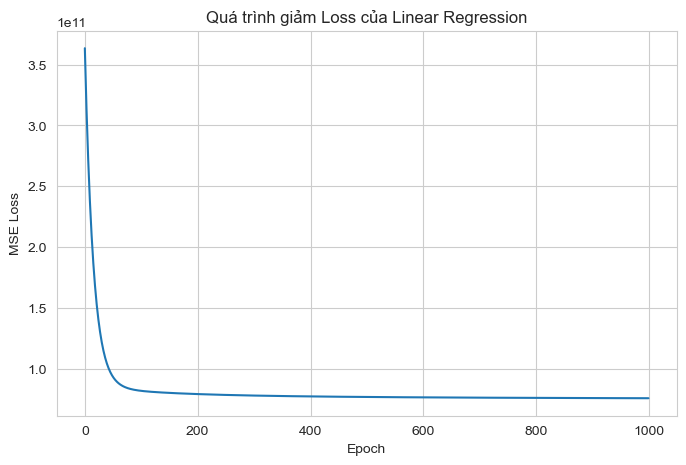

In [10]:
#Vẽ đồ thị Loss theo Epoch
plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Quá trình giảm Loss của Linear Regression")
plt.grid(True)
plt.savefig('output/figures/Loss Function during Gradient Descent.png', dpi=150)
plt.show()

**Nhận xét:** Đồ thị Loss giảm dần theo số Epoch và tiến tới trạng thái ổn định cho thấy thuật toán Gradient Descent đã hội tụ, tức là tìm được bộ trọng số (W,b) làm cực tiểu hàm mất mát MSE.

#### 3.2. Huấn luyện mô hình Random Forest Regression

Random Forest Regression là một mô hình học máy thuộc nhóm Ensemble Learning có cấu trúc phức tạp, bao gồm nhiều thành phần như xây dựng cây quyết định (Decision Tree), lựa chọn ngẫu nhiên đặc trưng (Random Feature Selection), lấy mẫu Bootstrap (Bootstrap Sampling), tính toán tiêu chí giảm phương sai (Variance Reduction – Gain) và tổng hợp kết quả dự đoán bằng Bagging. Việc cài đặt đầy đủ thuật toán từ đầu đòi hỏi số lượng lớn mã nguồn cùng nhiều cấu trúc dữ liệu và thuật toán đệ quy, vượt quá phạm vi của bài tiểu luận.

Do đó sử dụng lớp RandomForestRegressor của thư viện scikit-learn để triển khai mô hình. Thư viện này là một công cụ mã nguồn mở được sử dụng rộng rãi trong nghiên cứu và thực tiễn, giúp bảo đảm tính chính xác, ổn định và khả năng tái lập kết quả.

Mặc dù sử dụng thư viện trong quá trình cài đặt, toàn bộ cơ sở toán học của thuật toán, bao gồm phương sai (Variance), tiêu chí giảm phương sai (Variance Reduction – Gain), Bootstrap Sampling, Random Feature Selection và Bagging Prediction đã được phân tích chi tiết trong báo cáo nhằm làm rõ nguyên lý hoạt động của mô hình.

In [11]:
# Khởi tạo mô hình
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42
)

# Huấn luyện mô hình

rf_model.fit(
    X_train_scaled,
    y_train
)

# Dự đoán trên tập Test
y_pred_rf = rf_model.predict(
    X_test_scaled
)


print("===== RANDOM FOREST REGRESSION =====")

print("Số lượng cây:", rf_model.n_estimators)

print("Độ sâu tối đa:", rf_model.max_depth)

print("\n5 giá trị dự đoán đầu tiên:")
print(y_pred_rf[:5])

===== RANDOM FOREST REGRESSION =====
Số lượng cây: 100
Độ sâu tối đa: 10

5 giá trị dự đoán đầu tiên:
[635749.38120424 473148.73001215 520025.14992894 537672.14703724
 522306.12971559]


In [12]:
comparison = pd.DataFrame({
    "Actual Price": y_test.to_numpy(),
    "Linear Regression": y_pred_lr,
    "Random Forest Regression": y_pred_rf
})

print(comparison.head(10))

   Actual Price  Linear Regression  Random Forest Regression
0        514764      532672.845380             635749.381204
1        694256      560460.297901             473148.730012
2         66375      462776.263110             520025.149929
3        650243      525623.590565             537672.147037
4        223285      539588.297795             522306.129716
5        468127      542499.750302             581006.647739
6        513002      544321.437537             547174.700703
7        911525      595729.977717             564439.076804
8        723265      520446.290258             589721.353639
9        339416      595339.750944             628250.290500


## 4. So sánh hiệu năng & Lựa chọn mô hình

Đo lường hiệu năng của từng thuật toán trên tập kiểm thử (Test set) bằng các chỉ số phù hợp: R^2 Score, RMSE, MAE.


In [13]:
#ĐÁNH GIÁ THỰC NGHIỆM

# Linear Regression vs Random Forest Regression
# Giá trị thực tế trên tập Test
y_true = y_test.to_numpy(dtype=float)

# Giá trị dự đoán của Linear Regression
y_pred_linear = np.asarray(y_pred_lr, dtype=float)

# Giá trị dự đoán của Random Forest
y_pred_rf_test = np.asarray(y_pred_rf, dtype=float)

# HÀM TÍNH R² SCORE
def calculate_r2(y_true, y_pred):

    # Tổng bình phương sai số dự đoán
    SS_res = np.sum(
        (y_true - y_pred) ** 2
    )

    # Tổng bình phương độ lệch so với giá trị trung bình
    SS_tot = np.sum(
        (y_true - np.mean(y_true)) ** 2
    )

    # R²
    R2 = 1 - (SS_res / SS_tot)

    return R2

#  HÀM TÍNH MAE
def calculate_mae(y_true, y_pred):

    MAE = np.mean(
        np.abs(y_true - y_pred)
    )

    return MAE

#  HÀM TÍNH RMSE
def calculate_rmse(y_true, y_pred):

    # Tính MSE
    MSE = np.mean(
        (y_true - y_pred) ** 2
    )

    # Lấy căn bậc hai
    RMSE = np.sqrt(MSE)

    return RMSE

#  ĐÁNH GIÁ LINEAR REGRESSION
r2_linear = calculate_r2(
    y_true,
    y_pred_linear
)

mae_linear = calculate_mae(
    y_true,
    y_pred_linear
)

rmse_linear = calculate_rmse(
    y_true,
    y_pred_linear
)

#  ĐÁNH GIÁ RANDOM FOREST
r2_rf = calculate_r2(
    y_true,
    y_pred_rf_test
)

mae_rf = calculate_mae(
    y_true,
    y_pred_rf_test
)
rmse_rf = calculate_rmse(
    y_true,
    y_pred_rf_test
)
# IN KẾT QUẢ
print("=" * 65)
print("KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST")
print("=" * 65)
print("\n--- Linear Regression ---")
print("R² Score :", round(r2_linear, 4))
print("RMSE     :", round(rmse_linear, 4))
print("MAE      :", round(mae_linear, 4))
print("\n--- Random Forest Regression ---")
print("R² Score :", round(r2_rf, 4))
print("RMSE     :", round(rmse_rf, 4))
print("MAE      :", round(mae_rf, 4))

# TẠO BẢNG KẾT QUẢ
results = pd.DataFrame({

    "Mô hình": [
        "Linear Regression",
        "Random Forest Regression"
    ],

    "R² Score": [
        r2_linear,
        r2_rf
    ],

    "RMSE": [
        rmse_linear,
        rmse_rf
    ],

    "MAE": [
        mae_linear,
        mae_rf
    ]
})

print("\n")
print("=" * 65)
print("BẢNG ĐÁNH GIÁ HIỆU NĂNG")
print("=" * 65)
print(results.round(4).to_string(index=False))

KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST

--- Linear Regression ---
R² Score : -0.0111
RMSE     : 280473.8087
MAE      : 243137.4243

--- Random Forest Regression ---
R² Score : -0.0526
RMSE     : 286162.7792
MAE      : 248811.0178


BẢNG ĐÁNH GIÁ HIỆU NĂNG
                 Mô hình  R² Score        RMSE         MAE
       Linear Regression   -0.0111 280473.8087 243137.4243
Random Forest Regression   -0.0526 286162.7792 248811.0178


Kết quả thực nghiệm trên tập kiểm thử cho thấy Linear Regression đạt hiệu năng tốt hơn Random Forest Regression trong cả ba chỉ tiêu R
2
, RMSE và MAE. Tuy nhiên, việc cả hai mô hình đều có R
2
<0 cho thấy khả năng dự đoán của các mô hình trên tập kiểm thử còn hạn chế. Do đó, mặc dù Linear Regression là mô hình có kết quả tốt hơn trong hai thuật toán được thử nghiệm, hiệu năng tổng thể vẫn chưa cao và cần được xem xét thêm về đặc trưng dữ liệu, cách xây dựng mô hình hoặc các yếu tố có khả năng ảnh hưởng đến giá nhà nhưng chưa được đưa vào bộ dữ liệu.

#### Biểu đồ so sánh R², RMSE, MAE giữa hai mô hình trên Test.

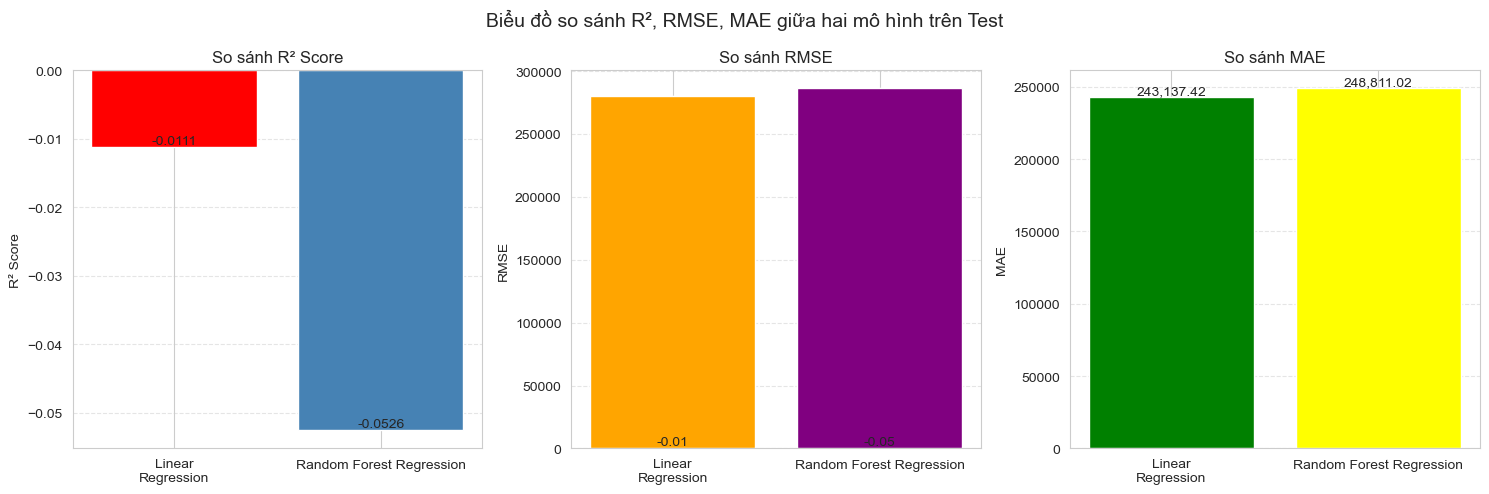

In [14]:
metrics = ["R² Score", "RMSE", "MAE"]
linear_values = [r2_linear,rmse_linear,mae_linear]
rf_values = [r2_rf,rmse_rf,mae_rf]
fig, axes = plt.subplots(1, 3,figsize=(15, 5))
# R²
axes[0].bar(["Linear\nRegression", "Random Forest Regression"],[r2_linear, r2_rf],color=["red","steelblue"])
axes[0].set_title("So sánh R² Score")
axes[0].set_ylabel("R² Score")
axes[0].grid(axis="y",linestyle="--",alpha=0.5)
# Hiển thị giá trị trên cột
for i, value in enumerate([r2_linear, r2_rf]):
    axes[0].text(i,value,f"{value:.4f}",ha="center",va="bottom")
    
# RMSE
    axes[1].bar(["Linear\nRegression", "Random Forest Regression"],[rmse_linear, rmse_rf],color=["orange","purple"])
    axes[1].set_title("So sánh RMSE")
    axes[1].set_ylabel("RMSE")
    axes[1].grid(axis="y",linestyle="--",alpha=0.5)
    axes[1].text(i,value,f"{value:,.2f}",ha="center",va="bottom")
# MAE
    axes[2].bar(["Linear\nRegression", "Random Forest Regression"],[mae_linear, mae_rf],color=["green","yellow"])
    axes[2].set_title("So sánh MAE")
    axes[2].set_ylabel("MAE")
    axes[2].grid(axis="y",linestyle="--",alpha=0.5)
for i, value in enumerate([mae_linear, mae_rf]):
    axes[2].text(i,value,f"{value:,.2f}",ha="center",va="bottom")
fig.suptitle("Biểu đồ so sánh R², RMSE, MAE giữa hai mô hình trên Test",fontsize=14)
plt.tight_layout()
plt.savefig('output/figures/Biểu đồ so sánh R², RMSE, MAE giữa hai mô hình trên Test.png', dpi=150)
plt.show()

#### Biểu đồ Giá thực tế – Giá dự đoán, có đường chéo lý tưởng y=x bằng nét đứt màu đỏ.

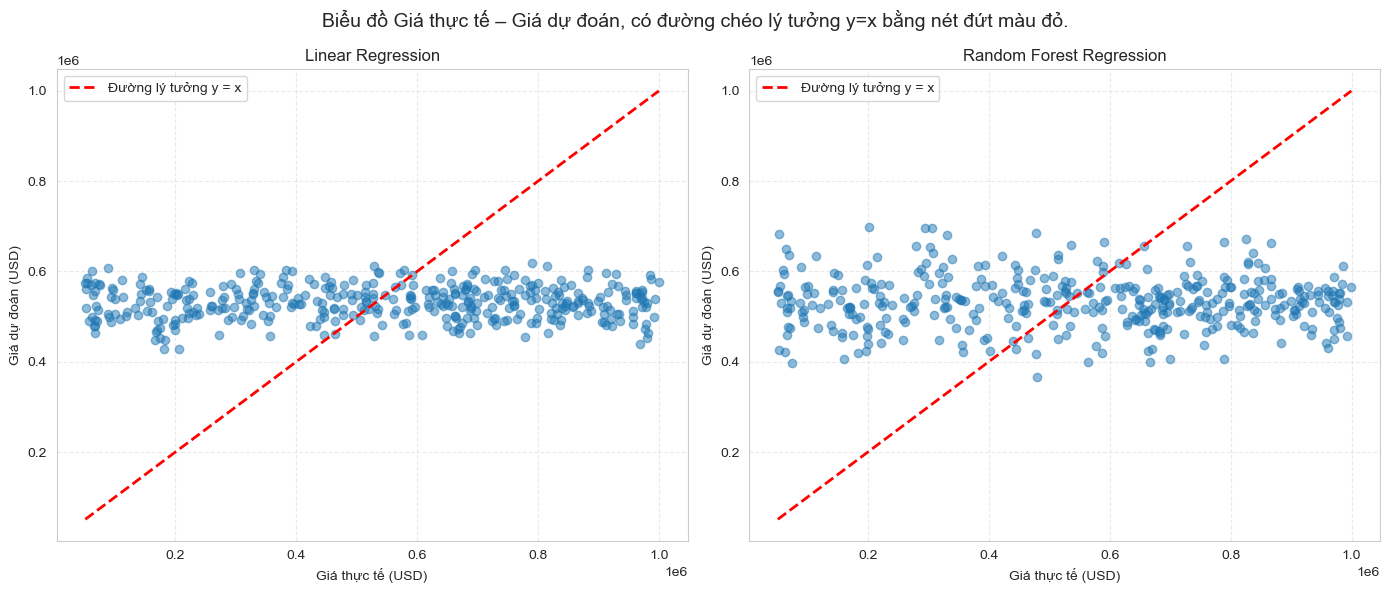

In [15]:
y_actual = y_test.to_numpy(dtype=float)
y_pred_linear = np.asarray(y_pred_lr,dtype=float)
y_pred_random_forest = np.asarray(y_pred_rf,dtype=float)
min_price = min(y_actual.min(),y_pred_linear.min(),y_pred_random_forest.min())
max_price = max(y_actual.max(),y_pred_linear.max(),y_pred_random_forest.max())
fig, axes = plt.subplots(1,2,figsize=(14, 6))
axes[0].scatter(y_actual,y_pred_linear,alpha=0.5)
axes[0].plot([min_price, max_price],[min_price, max_price],linestyle="--",color="red",linewidth=2,label="Đường lý tưởng y = x")
axes[0].set_title("Linear Regression")
axes[0].set_xlabel("Giá thực tế (USD)")
axes[0].set_ylabel("Giá dự đoán (USD)")
axes[0].legend()
axes[0].grid(linestyle="--",alpha=0.4)
axes[1].scatter(y_actual,y_pred_random_forest,alpha=0.5)
axes[1].plot([min_price, max_price],[min_price, max_price],linestyle="--",color="red",linewidth=2,label="Đường lý tưởng y = x")
axes[1].set_title("Random Forest Regression")
axes[1].set_xlabel("Giá thực tế (USD)")
axes[1].set_ylabel("Giá dự đoán (USD)")
axes[1].legend()
axes[1].grid(linestyle="--",alpha=0.4)
fig.suptitle(
    "Biểu đồ Giá thực tế – Giá dự đoán, có đường chéo lý tưởng y=x bằng nét đứt màu đỏ.",
    fontsize=14
)
plt.tight_layout()
plt.savefig('output/figures/Biểu đồ Giá thực tế – Giá dự đoán, có đường chéo lý tưởng y=x bằng nét đứt màu đỏ..png', dpi=150)
plt.show()

Kết quả trực quan từ biểu đồ và các chỉ số đánh giá cho thấy cả Linear Regression và Random Forest Regression đều có khả năng dự đoán giá nhà còn hạn chế trên tập kiểm thử. Các điểm dự đoán của cả hai mô hình chưa bám sát đường tham chiếu y=x, đồng thời giá trị R
2
 đều nhỏ hơn 0. Trong hai mô hình, Linear Regression cho kết quả tốt hơn, thể hiện qua R
2
 cao hơn và RMSE, MAE thấp hơn. Tuy nhiên, mức sai số vẫn tương đối lớn, cho thấy các đặc trưng hiện tại chưa đủ để mô hình giải thích tốt sự biến động của giá nhà. Vì vậy, kết quả thực nghiệm là cơ sở để đánh giá hạn chế của mô hình và xem xét khả năng cải thiện thông qua lựa chọn đặc trưng, xây dựng thêm đặc trưng hoặc tối ưu tham số mô hình.

#### Kiểm tra Overfitting

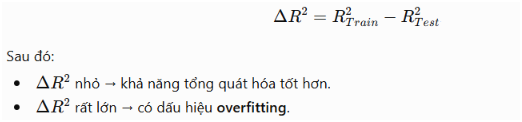

In [16]:
# R² TRÊN TẬP TRAIN
# Linear Regression
y_pred_lr_train = np.dot(X_train_lr, W) + b
r2_linear_train = calculate_r2(y_train_lr,y_pred_lr_train)
# Random Forest
y_pred_rf_train = rf_model.predict(X_train_scaled)
r2_rf_train = calculate_r2(y_train.to_numpy(dtype=float),y_pred_rf_train)
# CHÊNH LỆCH R² TRAIN - TEST
r2_gap_linear = r2_linear_train - r2_linear
r2_gap_rf = r2_rf_train - r2_rf
print("===== R² TRAIN - TEST =====")
print("Linear Regression:")
print("R² Train:", round(r2_linear_train, 4))
print("R² Test :", round(r2_linear, 4))
print("Chênh lệch:", round(r2_gap_linear, 4))
print("\nRandom Forest:")
print("R² Train:", round(r2_rf_train, 4))
print("R² Test :", round(r2_rf, 4))
print("Chênh lệch:", round(r2_gap_rf, 4))

===== R² TRAIN - TEST =====
Linear Regression:
R² Train: 0.0024
R² Test : -0.0111
Chênh lệch: 0.0136

Random Forest:
R² Train: 0.5014
R² Test : -0.0526
Chênh lệch: 0.554


===== Feature Importance - Random Forest Regression =====
Area                 0.341417
YearBuilt            0.260694
Bedrooms             0.089086
Bathrooms            0.072207
Floors               0.048893
Garage               0.029652
Location_Rural       0.028664
Condition_Fair       0.028285
Location_Urban       0.028257
Location_Suburban    0.025843
Condition_Good       0.024802
Condition_Poor       0.022200
dtype: float64


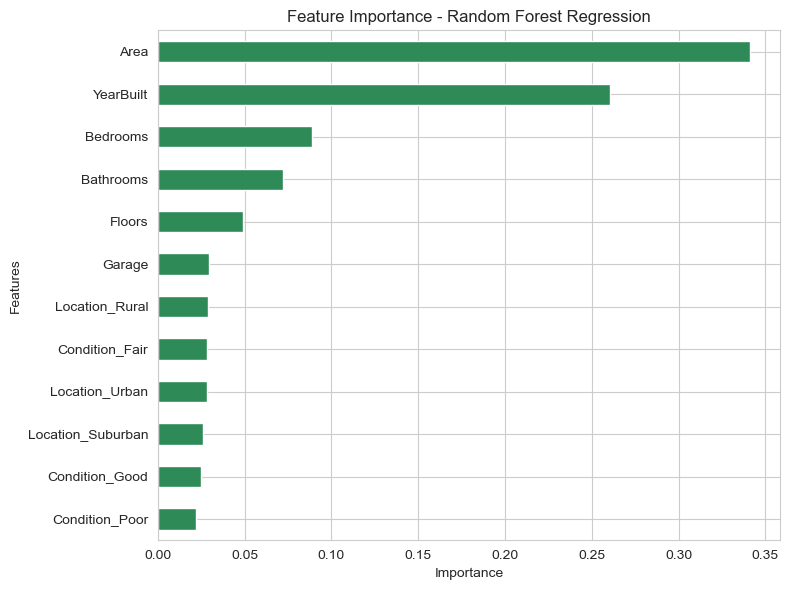

In [17]:
# Feature Importance - Random Forest Regression
# Lấy tên các đặc trưng từ dữ liệu Train
feature_names = X_train_scaled.columns

# Tạo Series Feature Importance
feat_importance = pd.Series(
    rf_model.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

# In kết quả
print("===== Feature Importance - Random Forest Regression =====")
print(feat_importance)
# VẼ BIỂU ĐỒ
plt.figure(figsize=(8, 6))

feat_importance.sort_values().plot(
    kind='barh',
    color='seagreen'
)

plt.title("Feature Importance - Random Forest Regression")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.savefig('output/figures/Feature Importance - Random Forest.png', dpi=150)
plt.show()

Kết quả Feature Importance cho thấy mức độ đóng góp của các biến đầu vào đối với mô hình Random Forest. Các đặc trưng có giá trị Importance cao được xem là những biến có vai trò quan trọng hơn trong quá trình phân chia dữ liệu và dự đoán giá nhà. Ngược lại, các biến có giá trị Importance thấp có mức đóng góp tương đối nhỏ hơn. Kết quả này giúp bổ sung khả năng diễn giải cho Random Forest và cho phép xác định những đặc trưng có ảnh hưởng đáng kể đến quá trình dự đoán.

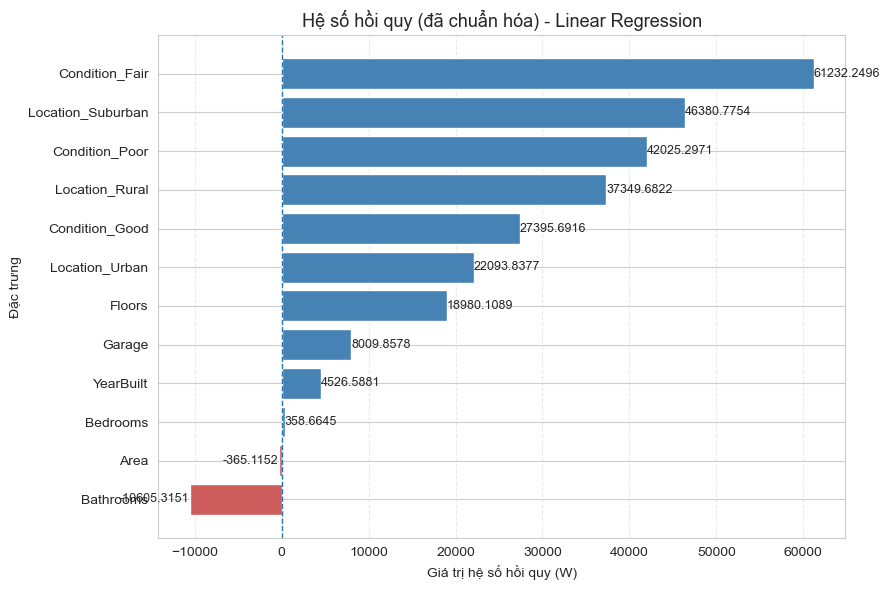

In [18]:
#  HỆ SỐ HỒI QUY CHUẨN HÓA CỦA LINEAR REGRESSION
# Lấy tên các đặc trưng
feature_names = X_train_scaled.columns

# Tạo Series hệ số hồi quy
coef_lr = pd.Series(
    W,
    index=feature_names
).sort_values()

# Hệ số dương: xanh
# Hệ số âm: đỏ
colors = [
    'steelblue' if value >= 0 else 'indianred'
    for value in coef_lr.values
]

# VẼ BIỂU ĐỒ
# ============================================================

plt.figure(figsize=(9, 6))

bars = plt.barh(
    coef_lr.index,
    coef_lr.values,
    color=colors
)

# Đường tham chiếu tại hệ số = 0
plt.axvline(
    x=0,
    linestyle='--',
    linewidth=1
)

# Hiển thị giá trị hệ số
for bar, value in zip(bars, coef_lr.values):

    if value >= 0:
        x = value + 0.002
        ha = 'left'
    else:
        x = value - 0.002
        ha = 'right'

    plt.text(
        x,
        bar.get_y() + bar.get_height() / 2,
        f'{value:.4f}',
        va='center',
        ha=ha,
        fontsize=9
    )

# ============================================================
# TIÊU ĐỀ VÀ NHÃN
# ============================================================

plt.title('Hệ số hồi quy (đã chuẩn hóa) - Linear Regression',fontsize=13)
plt.xlabel('Giá trị hệ số hồi quy (W)')
plt.ylabel('Đặc trưng')
plt.grid( axis='x',linestyle='--',alpha=0.4)
plt.tight_layout()
plt.savefig('output/figures/Hình 4.4 - Hệ số hồi quy chuẩn hóa Linear Regression.png',dpi=300,bbox_inches='tight')
plt.show()

#### Quyết định chọn mô hình
Từ các kết quả trên, Linear Regression được lựa chọn là mô hình phù hợp nhất cho bộ dữ liệu nghiên cứu. Mô hình không chỉ đạt hiệu năng tốt hơn Random Forest Regression trên cả R2, RMSE và MAE của tập Test mà còn có mức chênh lệch Train–Test thấp hơn đáng kể, cho thấy khả năng tổng quát hóa ổn định hơn. Bên cạnh đó, Linear Regression có cấu trúc đơn giản, chi phí tính toán thấp và khả năng diễn giải cao, phù hợp với mục tiêu vừa dự đoán vừa phân tích mối quan hệ giữa các đặc trưng và giá nhà.

Tuy nhiên, cần lưu ý rằng cả hai mô hình đều chưa đạt hiệu quả dự báo cao về mặt tuyệt đối, thể hiện qua giá trị R2 trên tập Test đều nhỏ hơn 0. Vì vậy, kết luận Linear Regression là mô hình phù hợp nhất chỉ mang ý nghĩa so sánh tương đối giữa hai thuật toán được nghiên cứu, không đồng nghĩa với việc mô hình đã đạt độ chính xác dự báo tối ưu cho bài toán giá nhà. Kết quả này cho thấy cần tiếp tục cải thiện mô hình thông qua việc xây dựng thêm đặc trưng, lựa chọn biến phù hợp hoặc thử nghiệm các thuật toán hồi quy khác trong các nghiên cứu tiếp theo.